# 01 · Data overview

What is in `mart_ipo_analytics`, how complete it is, and what it can be used for.

- **Rows:** one per IPO listed on NSE (mainboard and SME) from the NSE past-issues feed, which starts in 2016.
- **Segments:** mainboard and SME are shown side by side and never pooled. SME issues are around 25× smaller, have different investor categories and, since July 2024, a capped listing price.
- **Returns:** price returns in percent, adjusted for splits and bonuses, not dividends.
  - `listing_gain_pct`: listing-day open vs issue price.
  - `excess_return_1y_pct`: return from issue price one year after listing, minus the NIFTY 50 return over the same dates, in percentage points.

Build the mart first: `python pipeline.py --snapshot 2026-02-15 --skip-scrape`. Set `IPO_SNAPSHOT` to pick a different snapshot.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pipeline.py').exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import SEGMENTS
from src.data import HORIZONS, horizon_elapsed, load_funnel, load_mart
from src.plotting import MUTED, SEGMENT_COLORS, SEGMENT_LABELS, apply_style, asinh_bins, percent_axis, save_fig

apply_style()
pd.set_option('display.float_format', '{:,.1f}'.format)
pd.set_option('display.max_colwidth', 80)

df = load_mart()
SNAPSHOT = df['snapshot_date'].iloc[0].date()
listed = df[df['has_listing_price']]

print(f"Snapshot {SNAPSHOT}: {len(df):,} listed IPOs, "
      f"listing dates {df['listing_dt'].min():%d %b %Y} to {df['listing_dt'].max():%d %b %Y}")
df.groupby('segment', observed=True).size().rename('ipos').to_frame().T

Snapshot 2026-02-15: 1,143 listed IPOs, listing dates 08 Feb 2016 to 02 Jan 2026


segment,MAINBOARD,SME
ipos,452,691


## 1 · Coverage

### 1.1 Join funnel

Row counts from the raw NSE feed to the mart, then how many IPOs have each extra source. Nothing is dropped after step 4; missing sources are flags, not filters.

In [2]:
load_funnel()

,step,stage,description,ALL,MAINBOARD,SME
0,1,raw_nse_issues,All rows in the NSE past-issues feed,1412,<NA>,<NA>
1,2,equity_issues,"Security type EQ, BE or SME",1170,467,703
2,3,ipos,"Excluding FPOs, withdrawn, partly-paid and follow-on issues",1154,457,697
3,4,listed_ipos,"Traded on NSE after issue close, or has a listing date in the feed",1143,452,691
4,5,mart_rows,Rows in mart_ipo_analytics,1143,452,691
5,6,with_subscription_data,Matched to a Chittorgarh subscription record,1110,450,660
6,7,with_market_data,Matched to a Tickertape stock,1128,449,679
7,8,with_both,Subscription and market data,1096,447,649
8,9,with_listing_price,Listing-day open and close from the NSE bhavcopy,1141,450,691
9,10,with_return_1y,One year since listing has passed and the stock still traded,929,356,573


### 1.2 IPOs by listing year

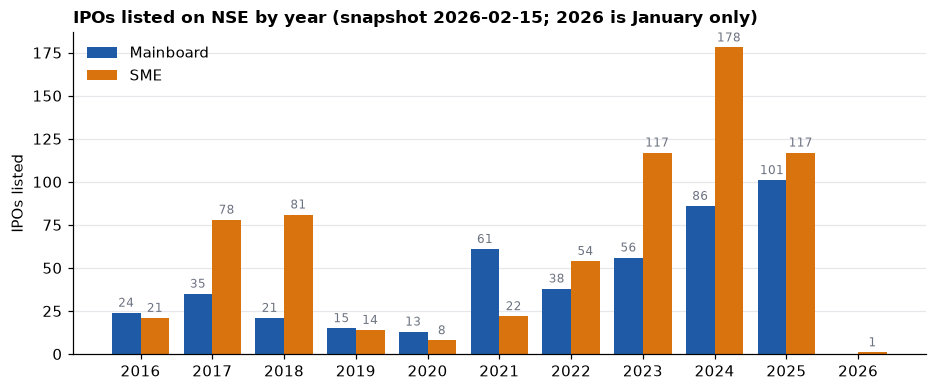

listing_year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
segment,,,,,,,,,,,
MAINBOARD,24,35,21,15,13,61,38,56,86,101,0
SME,21,78,81,14,8,22,54,117,178,117,1
ALL,45,113,102,29,21,83,92,173,264,218,1


In [3]:
counts = pd.crosstab(df['listing_year'], df['segment'])
counts['ALL'] = counts.sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 3.8))
years = counts.index.astype(int)
width = 0.4
for offset, segment in zip((-width / 2, width / 2), SEGMENTS):
    bars = ax.bar(years + offset, counts[segment], width, color=SEGMENT_COLORS[segment],
                  label=SEGMENT_LABELS[segment])
    ax.bar_label(bars, labels=[f'{v:.0f}' if v else '' for v in counts[segment]], fontsize=8, padding=2,
                 color=MUTED)
ax.set_xticks(years)
ax.set_ylabel('IPOs listed')
ax.set_title(f'IPOs listed on NSE by year (snapshot {SNAPSHOT}; 2026 is January only)')
ax.legend(loc='upper left')
ax.grid(axis='x', visible=False)
save_fig(fig, '01_ipo_count_by_year')
plt.show()

counts.T

### 1.3 What is available, by segment

Share of IPOs that have each field. Horizon returns only count IPOs whose horizon has passed by the snapshot date; the rest are not missing, they are not due yet.

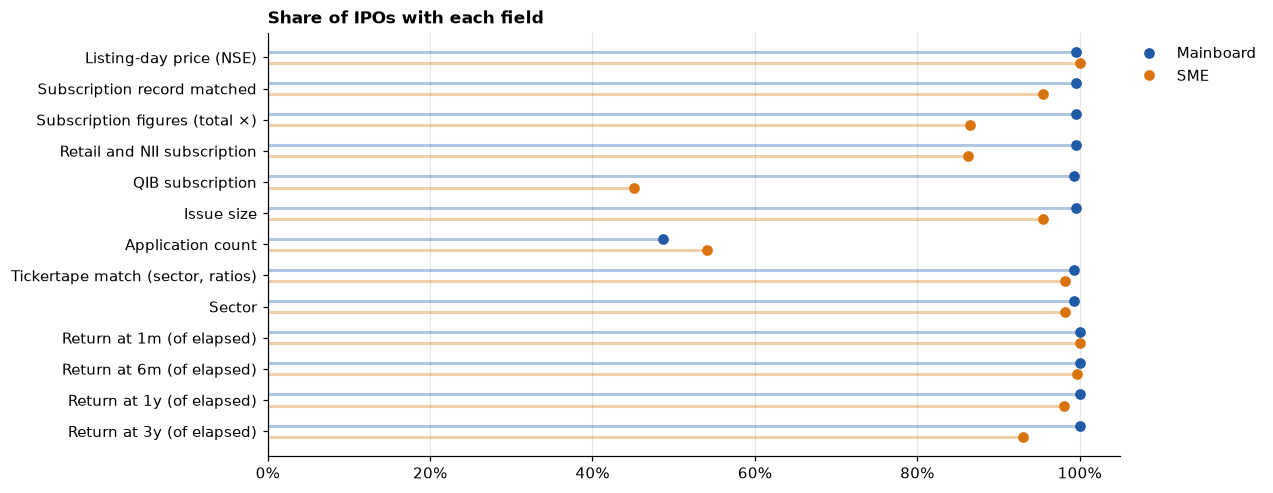

segment,MAINBOARD,SME
Listing-day price (NSE),99.6,100.0
Subscription record matched,99.6,95.5
Subscription figures (total ×),99.6,86.5
Retail and NII subscription,99.6,86.3
QIB subscription,99.3,45.2
Issue size,99.6,95.5
Application count,48.7,54.1
"Tickertape match (sector, ratios)",99.3,98.3
Sector,99.3,98.3
Return at 1m (of elapsed),100.0,100.0


,1m elapsed,6m elapsed,1y elapsed,3y elapsed
segment,,,,
MAINBOARD,450,388,356,209
SME,691,644,584,285


In [4]:
def share(mask, base=None):
    base = pd.Series(True, index=df.index) if base is None else base
    return (mask & base).groupby(df['segment'], observed=True).sum() / base.groupby(df['segment'], observed=True).sum() * 100

has_figures = df['has_subscription_figures']
availability = {
    'Listing-day price (NSE)': share(df['has_listing_price']),
    'Subscription record matched': share(df['has_subscription_data']),
    'Subscription figures (total ×)': share(has_figures),
    'Retail and NII subscription': share(df['subscription_retail_x'].notna() & df['subscription_nii_x'].notna()),
    'QIB subscription': share(df['subscription_qib_x'].notna()),
    'Issue size': share(df['issue_size_cr'].notna()),
    'Application count': share(df['applications'].notna()),
    'Tickertape match (sector, ratios)': share(df['has_market_data']),
    'Sector': share(df['sector'].notna()),
}
for horizon in HORIZONS:
    elapsed = horizon_elapsed(df, horizon)
    availability[f'Return at {horizon} (of elapsed)'] = share(df[f'return_{horizon}_pct'].notna(), elapsed)

availability = pd.DataFrame(availability).T
elapsed_counts = pd.DataFrame({f'{h} elapsed': horizon_elapsed(df, h).groupby(df['segment'], observed=True).sum()
                               for h in HORIZONS})

fig, ax = plt.subplots(figsize=(10, 5))
rows = availability.index[::-1]
y = np.arange(len(rows))
for offset, segment in zip((0.18, -0.18), SEGMENTS):
    values = availability.loc[rows, segment]
    ax.hlines(y + offset, 0, values, color=SEGMENT_COLORS[segment], alpha=0.35, linewidth=2)
    ax.plot(values, y + offset, 'o', color=SEGMENT_COLORS[segment], label=SEGMENT_LABELS[segment])
ax.set_yticks(y, rows)
ax.set_xlim(0, 105)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.set_title('Share of IPOs with each field')
ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
ax.grid(axis='y', visible=False)
save_fig(fig, '01_data_availability')
plt.show()

display(availability)
elapsed_counts

### 1.4 Which gaps are structural

Missing QIB subscription and application counts come from how issues and the source were structured in each year, not from failed joins. The tables show the share of IPOs that have each, among those with subscription figures.

In [5]:
with_figures = df[df['has_subscription_figures']]
structural = pd.DataFrame({
    'IPOs with figures': with_figures.groupby(['listing_year', 'segment'], observed=True).size(),
    'with QIB category %': with_figures.groupby(['listing_year', 'segment'], observed=True)['has_qib_category'].mean() * 100,
    'with application count %': with_figures.groupby(['listing_year', 'segment'], observed=True)['applications']
                                 .apply(lambda s: s.notna().mean() * 100),
}).unstack('segment')
structural

IPOs with figures       with QIB category %        \
segment              MAINBOARD   SME           MAINBOARD   SME   
listing_year                                                     
2016                      24.0   NaN               100.0  <NA>   
2017                      34.0   9.0               100.0  11.1   
2018                      21.0  78.0               100.0   7.7   
2019                      14.0  14.0               100.0   0.0   
2020                      13.0   8.0               100.0   0.0   
2021                      61.0  22.0               100.0   4.5   
2022                      38.0  54.0               100.0  16.7   
2023                      56.0 117.0               100.0  46.2   
2024                      86.0 178.0               100.0  75.8   
2025                     101.0 117.0               100.0  89.7   
2026                       NaN   1.0                <NA> 100.0   

             with application count %        
segment                     MAINBOARD   SME  
listing_year                                 
2016                              0.0   NaN  
2017                              0.0   0.0  
2018                              0.0   0.0  
2019                              0.0   0.0  
2020                              0.0   0.0  
2021                              0.0   0.0  
2022                              0.0   0.0  
2023                             83.9  76.9  
2024                             91.9  96.1  
2025                             92.1  95.7  
2026                              NaN 100.0

In [6]:
def breakdown(frame):
    segments = {s: int(n) for s, n in frame['segment'].value_counts().items() if n}
    years = {int(y): int(n) for y, n in frame['listing_year'].value_counts().sort_index().items()}
    return f"{len(frame)} IPOs, by segment {segments}, by listing year {years}"

print("Matched subscription record but no figures:", breakdown(df[df['has_subscription_data'] & ~df['has_subscription_figures']]))
print("No subscription record at all:", breakdown(df[~df['has_subscription_data']]))

Matched subscription record but no figures: 62 IPOs, by segment {'SME': 62}, by listing year {2017: 59, 2018: 3}
No subscription record at all: 33 IPOs, by segment {'SME': 31, 'MAINBOARD': 2}, by listing year {2016: 21, 2017: 11, 2019: 1}


**Reading the coverage (snapshot 2026-02-15):**

- **Listing prices and horizon returns are near complete** in both segments: 1,141 of 1,143 IPOs have a listing-day price (CAMS and PROTEAN listed on BSE only), and every due 1-month return exists.
- **Subscription figures are complete for mainboard (450 of 452) but not for SME (598 of 691).** The SME gap is almost entirely 2016–2017: Chittorgarh has no SME records for 2016 and lists most 2017 SME issues without numbers. In practice, **SME subscription analysis starts in 2018.**
- **QIB subscription is structural for SME.** Every mainboard IPO has a QIB category. Among SME IPOs with figures, the share with one is below 17% in every year up to 2022, then 46% (2023), 76% (2024) and 90% (2025). SME IPOs with a QIB category are therefore mostly recent issues, not a random subset.
- **Application counts only exist from 2023**, in both segments. They can't be used for trends before that.

## 2 · Distributions

Both returns are heavily right-skewed, so the x axis is linear between −10% and +10% and logarithmic beyond (an asinh scale). The dashed line is the median. Bins are equal width on that scale, so bins near zero cover only a point or two and look emptier than they are. The dip around 0 in the 1-year panels comes from the scale, not from two separate groups of outcomes.

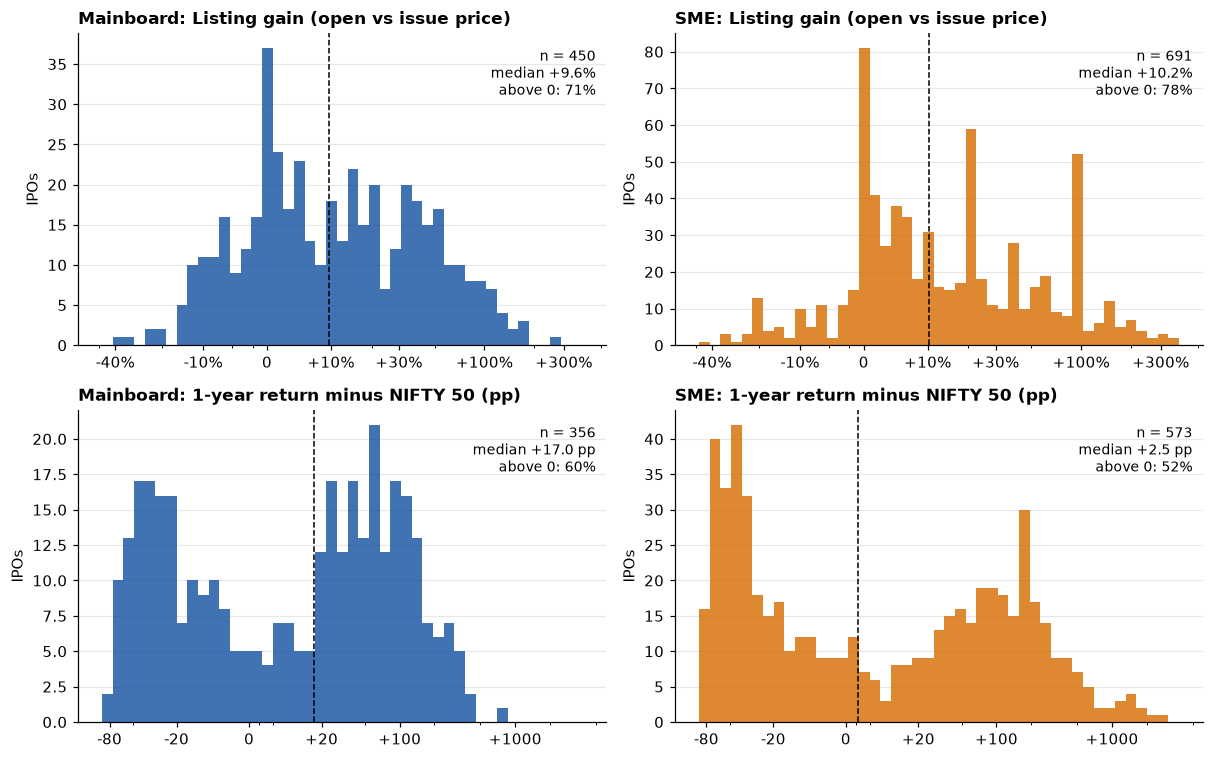

In [7]:
DISTRIBUTIONS = {
    'listing_gain_pct': ('Listing gain (open vs issue price)', [-40, -10, 0, 10, 30, 100, 300], '%'),
    'excess_return_1y_pct': ('1-year return minus NIFTY 50 (pp)', [-80, -20, 0, 20, 100, 1000], ' pp'),
}

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex='row')
for row, (column, (title, ticks, unit)) in zip(axes, DISTRIBUTIONS.items()):
    edges = asinh_bins(df[column].dropna(), n_bins=45)
    for ax, segment in zip(row, SEGMENTS):
        values = df.loc[df['segment'] == segment, column].dropna()
        ax.hist(values, bins=edges, color=SEGMENT_COLORS[segment], alpha=0.85)
        ax.set_xscale('asinh', linear_width=10)
        ax.set_xticks(ticks)
        ax.xaxis.set_major_formatter(lambda v, _, unit=unit: (f'{v:+.0f}%' if unit == '%' else f'{v:+.0f}') if v else '0')
        median = values.median()
        ax.axvline(median, color='black', linestyle='--', linewidth=1)
        ax.set_title(f'{SEGMENT_LABELS[segment]}: {title}')
        ax.text(0.98, 0.95, f'n = {len(values):,}\nmedian {median:+.1f}{unit}\nabove 0: {(values > 0).mean():.0%}',
                transform=ax.transAxes, ha='right', va='top', fontsize=9)
        ax.set_ylabel('IPOs')
        ax.grid(axis='x', visible=False)
fig.tight_layout()
save_fig(fig, '01_return_distributions')
plt.show()

In [8]:
summary_columns = ['listing_gain_pct', 'listing_day_close_gain_pct', 'excess_return_1y_pct', 'excess_return_3y_pct']
df.groupby('segment', observed=True)[summary_columns].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T

segment                           MAINBOARD      SME
listing_gain_pct           count      450.0    691.0
                           mean        21.0     30.9
                           std         34.4     54.2
                           min        -39.6    -48.1
                           10%         -6.7     -2.4
                           25%          0.0      1.0
                           50%          9.6     10.2
                           75%         33.3     40.0
                           90%         60.4     90.0
                           max        249.7    386.7
listing_day_close_gain_pct count      450.0    691.0
                           mean        22.0     32.2
                           std         36.4     55.7
                           min        -36.6    -45.5
                           10%         -8.5     -5.0
                           25%         -1.2      0.8
                           50%         12.4     12.3
                           75%         33.0     44.4
                           90%         62.1     99.5
                           max        267.2    411.0
excess_return_1y_pct       count      356.0    573.0
                           mean        37.5     87.7
                           std         90.6    300.9
                           min        -83.0    -93.0
                           10%        -43.1    -60.1
                           25%        -20.2    -37.5
                           50%         17.0      2.5
                           75%         65.4    100.9
                           90%        131.4    251.1
                           max        741.6  3,790.2
excess_return_3y_pct       count      209.0    265.0
                           mean        56.3    224.0
                           std        189.1    910.8
                           min       -124.4   -138.9
                           10%        -90.1   -102.1
                           25%        -58.5    -70.7
                           50%         -3.5     -8.3
                           75%        104.5    160.7
                           90%        253.9    530.4
                           max      1,303.2 10,878.9

The spikes in the SME listing-gain histogram come from rules and pricing conventions, not noise:

- **0%:** about 7% of IPOs in both segments open exactly at the issue price.
- **+90%:** since 4 July 2024 NSE caps an SME IPO's opening price at 90% above the issue price ([Business Standard, 4 Jul 2024](https://www.business-standard.com/markets/ipo/sme-ipo-opening-price-to-be-capped-at-90-in-pre-open-on-listing-day-nse-124070400429_1.html)).
- **+20%:** until April 2018 no SME listing opened above +20%, and many opened at exactly +20%. That matches the 20% daily price band on NSE Emerge applying on listing day, but the circular that ended it was not found, so it is treated as an observed ceiling rather than a documented rule.

In both capped periods an opening at the ceiling only says demand was *at least* that high.

In [9]:
at_issue = listed['listing_gain_pct'].eq(0)
capped = df[df['listing_cap_applies'].fillna(False)]
print(f"Opened exactly at the issue price: {at_issue.sum()} IPOs "
      f"({at_issue.groupby(listed['segment'], observed=True).mean().mul(100).round(1).to_dict()} % by segment)")
print(f"SME listings on or after 4 Jul 2024 (opening price capped at +90%): {len(capped)}, "
      f"of which {int(capped['listing_capped'].sum())} opened at the cap "
      f"({capped['listing_capped'].mean():.0%}); highest open {capped['listing_gain_pct'].max():+.1f}%")
pre_cap = df[(df['segment'] == 'SME') & ~df['listing_cap_applies'].fillna(False)]
print(f"SME listings before the cap that opened above +90%: {(pre_cap['listing_gain_pct'] > 90).sum()} of {len(pre_cap)}")

# The +20% spike: no SME listing opened above +20% until April 2018
sme = df[df['segment'] == 'SME'].sort_values('listing_dt')
first_above = sme[sme['listing_gain_pct'] > 20.005].iloc[0]
at_20 = sme['listing_gain_pct'].round(2).eq(20)
early = sme['listing_dt'] < first_above['listing_dt']
print(f"First SME listing that opened above +20%: {first_above['ticker']} on {first_above['listing_dt']:%d %b %Y} "
      f"({first_above['listing_gain_pct']:+.1f}%)")
print(f"SME listings before that: {early.sum()}, highest open {sme.loc[early, 'listing_gain_pct'].max():+.1f}%, "
      f"{(at_20 & early).sum()} at exactly +20%; at exactly +20% since: {(at_20 & ~early).sum()}")

Opened exactly at the issue price: 84 IPOs ({'MAINBOARD': 6.9, 'SME': 7.7} % by segment)
SME listings on or after 4 Jul 2024 (opening price capped at +90%): 211, of which 43 opened at the cap (20%); highest open +90.0%
SME listings before the cap that opened above +90%: 55 of 480
First SME listing that opened above +20%: MAHICKRA on 26 Apr 2018 (+40.0%)
SME listings before that: 134, highest open +20.0%, 46 at exactly +20%; at exactly +20% since: 3


## 3 · Base rates by year and segment

How often an IPO opened above its issue price, the median and interquartile range of the listing gain, and the median 1-year return over NIFTY. Years with fewer than 20 IPOs in a segment are drawn as hollow markers. The 1-year columns are only filled for listing years where every IPO has had a full year (2025 listings have not).

In [10]:
MIN_COHORT = 20

def cohort_stats(group):
    gain = group['listing_gain_pct']
    excess = group['excess_return_1y_pct']
    complete = horizon_elapsed(group, '1y').all()
    return pd.Series({
        'ipos': len(group),
        'opened_above_issue_%': (gain > 0).mean() * 100,
        'median_listing_gain': gain.median(),
        'q1_listing_gain': gain.quantile(0.25),
        'q3_listing_gain': gain.quantile(0.75),
        'ipos_with_1y': excess.notna().sum() if complete else np.nan,
        'beat_nifty_1y_%': (excess.dropna() > 0).mean() * 100 if complete else np.nan,
        'median_excess_1y': excess.median() if complete else np.nan,
    })

base_rates = (listed.groupby(['segment', 'listing_year'], observed=True)
              .apply(cohort_stats)
              .astype({'ipos': int}))
base_rates

ipos  opened_above_issue_%  median_listing_gain  \
segment   listing_year                                                    
MAINBOARD 2016            24                  75.0                  8.3   
          2017            35                  60.0                  5.0   
          2018            21                  52.4                  2.7   
          2019            15                  66.7                  8.9   
          2020            13                  69.2                 48.2   
          2021            61                  75.4                 17.4   
          2022            38                  65.8                  3.3   
          2023            56                  80.4                 16.5   
          2024            86                  77.9                 17.3   
          2025           101                  68.3                  5.4   
SME       2016            21                  85.7                  5.7   
          2017            78                  80.8                  9.8   
          2018            81                  71.6                  1.6   
          2019            14                  78.6                  1.3   
          2020             8                  62.5                  1.1   
          2021            22                  63.6                  3.7   
          2022            54                  79.6                 19.3   
          2023           117                  85.5                 18.4   
          2024           178                  87.1                 39.8   
          2025           117                  63.2                  5.9   
          2026             1                 100.0                 90.0   

                        q1_listing_gain  q3_listing_gain  ipos_with_1y  \
segment   listing_year                                                   
MAINBOARD 2016                      0.0             21.8          24.0   
          2017                      0.0             35.0          35.0   
          2018                     -5.2              5.0          21.0   
          2019                     -2.1             22.8          15.0   
          2020                     -5.8             87.5          13.0   
          2021                      0.4             52.6          61.0   
          2022                     -1.2             12.1          38.0   
          2023                      2.0             38.5          56.0   
          2024                      2.6             42.1          86.0   
          2025                      0.0             14.3           NaN   
SME       2016                      2.0             20.0          20.0   
          2017                      1.6             20.0          78.0   
          2018                      0.0              6.7          74.0   
          2019                      0.6              3.9          11.0   
          2020                      0.0              2.0           8.0   
          2021                      0.0              5.8          22.0   
          2022                      2.3             60.3          54.0   
          2023                      4.8             57.9         117.0   
          2024                      9.2             90.0         178.0   
          2025                     -0.1             23.3           NaN   
          2026                     90.0             90.0           NaN   

                        beat_nifty_1y_%  median_excess_1y  
segment   listing_year                                     
MAINBOARD 2016                     58.3              38.2  
          2017                     48.6              -4.4  
          2018                     42.9              -7.4  
          2019                     73.3              54.0  
          2020                     92.3              88.6  
          2021                     54.1              10.1  
          2022                     71.1              22.6  
          2023                     64.3              25

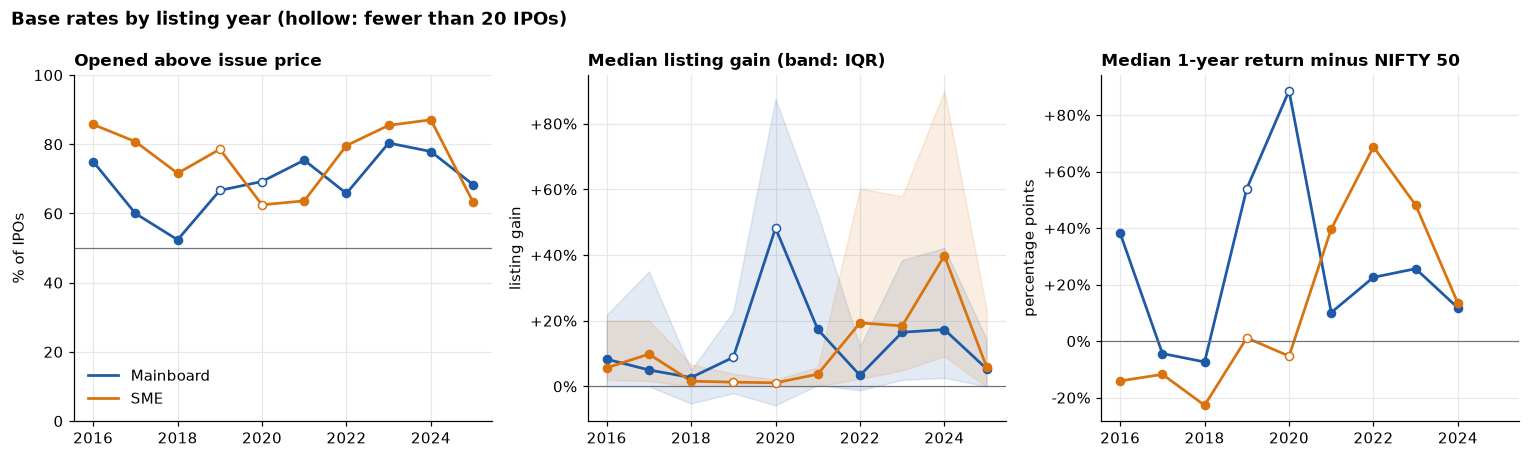

In [11]:
panels = [
    ('opened_above_issue_%', 'Opened above issue price', '% of IPOs'),
    ('median_listing_gain', 'Median listing gain (band: IQR)', 'listing gain'),
    ('median_excess_1y', 'Median 1-year return minus NIFTY 50', 'percentage points'),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
for ax, (column, title, ylabel) in zip(axes, panels):
    for segment in SEGMENTS:
        cohort = base_rates.loc[segment]
        cohort = cohort[cohort['ipos'] >= 2]
        years = cohort.index.astype(int)
        color = SEGMENT_COLORS[segment]
        if column == 'median_listing_gain':
            ax.fill_between(years, cohort['q1_listing_gain'], cohort['q3_listing_gain'], color=color, alpha=0.12)
        ax.plot(years, cohort[column], color=color, linewidth=1.8, label=SEGMENT_LABELS[segment])
        small = cohort['ipos'] < MIN_COHORT
        ax.scatter(years[~small], cohort.loc[~small, column], color=color, zorder=3, s=28)
        ax.scatter(years[small], cohort.loc[small, column], facecolor='white', edgecolor=color, zorder=3, s=28)
    ax.axhline(0 if column != 'opened_above_issue_%' else 50, color=MUTED, linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    if column != 'opened_above_issue_%':
        percent_axis(ax, 'y')
    ax.set_xticks(range(2016, 2026, 2))
axes[0].set_ylim(0, 100)
axes[0].legend(loc='lower left')
fig.suptitle(f'Base rates by listing year (hollow: fewer than {MIN_COHORT} IPOs)', x=0.01, ha='left',
             fontweight='bold')
fig.tight_layout()
save_fig(fig, '01_base_rates_by_year')
plt.show()

In [12]:
overall = listed.groupby('segment', observed=True).apply(cohort_stats).astype({'ipos': int})
overall.loc[:, ['ipos_with_1y', 'beat_nifty_1y_%', 'median_excess_1y']] = (
    listed[horizon_elapsed(listed, '1y')].groupby('segment', observed=True)
    .apply(lambda g: pd.Series({'ipos_with_1y': g['excess_return_1y_pct'].notna().sum(),
                                'beat_nifty_1y_%': (g['excess_return_1y_pct'].dropna() > 0).mean() * 100,
                                'median_excess_1y': g['excess_return_1y_pct'].median()}))
)
overall

,ipos,opened_above_issue_%,median_listing_gain,q1_listing_gain,q3_listing_gain,ipos_with_1y,beat_nifty_1y_%,median_excess_1y
segment,,,,,,,,
MAINBOARD,450,71.3,9.6,0.0,33.3,356.0,59.6,17.0
SME,691,78.4,10.2,1.0,40.0,573.0,52.0,2.5


**Reading the base rates (snapshot 2026-02-15):**

- **Most IPOs open above their issue price** (71% mainboard, 78% SME), but the typical gain is modest: the median is +9.6% and +10.2%, and the IQR runs from about 0% to +33% (mainboard) and +1% to +40% (SME).
- **The listing gain moves in cycles.** SME medians stayed between +1% and +4% from 2018 to 2021, then rose to +19% (2022) and +40% (2024), when 87% of SME IPOs opened above issue. In 2025 both segments cooled to around +5–6%. Mainboard's highest median (+48% in 2020) comes from only 13 IPOs.
- **One year on, mainboard IPOs have done better against NIFTY than SME IPOs**: median +17.0 pp and 60% beating the index, vs +2.5 pp and 52% for SME. SME outcomes are also more spread out: the interquartile range is −37 to +101 pp, against −20 to +65 pp for mainboard.
- **Cohorts differ a lot.** Among cohorts of 20 or more IPOs, the median 1-year excess return ranges from −23 pp (SME 2018) to +69 pp (SME 2022). A pattern found in one period can't be assumed to hold in others, which is why Phase 4 tests within years.

## 4 · Why `return_since_issue_pct` can't be compared across years

`return_since_issue_pct` runs from the issue price to the last trade before the snapshot. A 2017 IPO has had eight more years to compound than a 2025 IPO, so its median return is higher mostly because it is older. The fixed 1-year return measures every IPO over the same length of time.

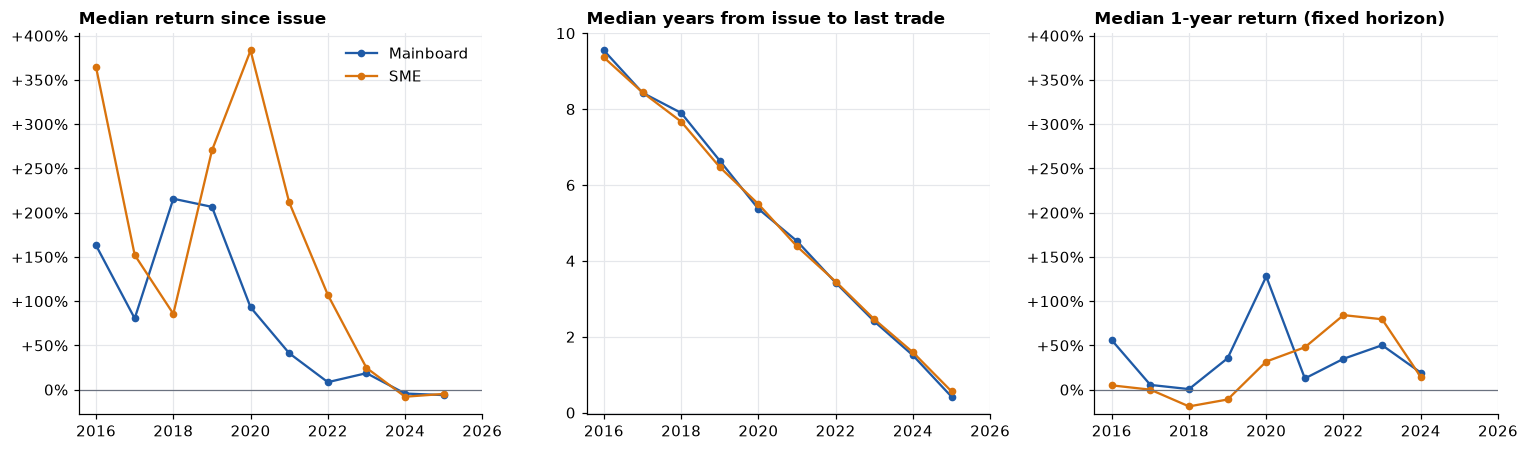

In [13]:
by_year = (listed.groupby(['segment', 'listing_year'], observed=True)
           .agg(ipos=('ticker', 'size'),
                median_return_since_issue=('return_since_issue_pct', 'median'),
                median_holding_years=('holding_years', 'median'),
                median_return_1y=('return_1y_pct', 'median'))
           .query('ipos >= 2'))
# Only listing years where every IPO has had a full year
complete_1y = horizon_elapsed(listed, '1y').groupby([listed['segment'], listed['listing_year']], observed=True).all()
by_year.loc[~complete_1y.reindex(by_year.index), 'median_return_1y'] = np.nan

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
panels = [
    ('median_return_since_issue', 'Median return since issue', True),
    ('median_holding_years', 'Median years from issue to last trade', False),
    ('median_return_1y', 'Median 1-year return (fixed horizon)', True),
]
for ax, (column, title, is_percent) in zip(axes, panels):
    for segment in SEGMENTS:
        series = by_year.loc[segment, column]
        ax.plot(series.index.astype(int), series, marker='o', markersize=4, color=SEGMENT_COLORS[segment],
                label=SEGMENT_LABELS[segment])
    ax.set_title(title)
    if is_percent:
        ax.axhline(0, color=MUTED, linewidth=0.8)
        percent_axis(ax, 'y')
    ax.set_xticks(range(2016, 2027, 2))
low = min(axes[0].get_ylim()[0], axes[2].get_ylim()[0])
high = max(axes[0].get_ylim()[1], axes[2].get_ylim()[1])
for ax in (axes[0], axes[2]):
    ax.set_ylim(low, high)
axes[0].legend()
fig.tight_layout()
save_fig(fig, '01_return_since_issue_bias')
plt.show()

In [14]:
from scipy.stats import spearmanr

rows = {}
for segment in SEGMENTS:
    seg = listed[listed['segment'] == segment]
    since = seg.dropna(subset=['holding_days', 'return_since_issue_pct'])
    fixed = seg.dropna(subset=['holding_days', 'return_1y_pct'])
    rows[segment] = {
        'rho(holding days, return since issue)': spearmanr(since['holding_days'], since['return_since_issue_pct']).statistic,
        'rho(holding days, 1-year return)': spearmanr(fixed['holding_days'], fixed['return_1y_pct']).statistic,
    }
pd.DataFrame(rows).map('{:.2f}'.format)

,MAINBOARD,SME
"rho(holding days, return since issue)",0.34,0.36
"rho(holding days, 1-year return)",0.04,-0.04


The longer an IPO has been held, the higher its return since issue (Spearman ρ 0.34 mainboard, 0.36 SME). With the fixed 1-year return, that link disappears (ρ 0.04 and −0.04). `return_since_issue_pct` stays in the mart as a descriptive field; **every comparison across IPOs uses a fixed-horizon return.**

## 5 · Survivorship and other caveats

In [15]:
not_trading = listed[listed['is_trading_at_snapshot'].eq(False)]
print(f"Stopped trading on NSE before the snapshot: {len(not_trading)} "
      f"({not_trading['segment'].value_counts().to_dict()})")

missing = []
for horizon in HORIZONS:
    elapsed = listed[horizon_elapsed(listed, horizon)]
    gone = elapsed[elapsed[f'return_{horizon}_pct'].isna()]
    missing.append({'horizon': horizon, 'elapsed': len(elapsed), 'no return': len(gone),
                    **{f'no return {s}': int((gone['segment'] == s).sum()) for s in SEGMENTS},
                    'of which after a price gap': int(gone['price_gap_dt'].notna().sum())})
pd.DataFrame(missing).set_index('horizon')

Stopped trading on NSE before the snapshot: 34 ({'SME': 30, 'MAINBOARD': 4})


,elapsed,no return,no return MAINBOARD,no return SME,of which after a price gap
horizon,,,,,
1m,1141,0,0,0,0
6m,1032,2,0,2,0
1y,940,11,0,11,0
3y,494,20,0,20,3


In [16]:
print("Stocks that stopped trading, with the returns they did record:")
(not_trading[['ticker', 'segment', 'listing_dt', 'last_trade_dt', 'listing_gain_pct', 'return_1y_pct', 'return_3y_pct']]
 .sort_values('listing_dt').reset_index(drop=True))

Stocks that stopped trading, with the returns they did record:


,ticker,segment,listing_dt,last_trade_dt,listing_gain_pct,return_1y_pct,return_3y_pct
0,EQUITAS,MAINBOARD,2016-04-21,2023-02-02,31.9,55.9,23.5
1,UJJIVAN,MAINBOARD,2016-05-10,2024-05-02,10.4,65.1,49.0
2,HUSYS,SME,2016-09-27,2021-06-30,5.7,-47.8,-44.9
3,JETKNIT,SME,2016-10-07,2025-12-08,20.0,68.0,-41.5
4,BOHRAIND,SME,2017-04-05,2021-12-29,2.2,-36.4,-98.8
5,ASLIND,SME,2017-04-18,2026-01-01,-5.4,-18.6,NaN
6,CKPPRODUCT,SME,2017-05-09,2020-08-20,0.0,37.0,NaN
7,SRIRAM,SME,2017-06-07,2024-02-26,20.0,-26.3,NaN
8,PUSHPREALM,SME,2017-07-10,2021-01-11,0.0,-5.5,-91.7
9,BANSAL,SME,2017-07-12,2020-07-06,9.7,321.0,-95.3


**Reading the survivorship check:**

- **Horizon returns come from NSE's own price files, not from Tickertape.** A company that later stopped trading still has every return it lived long enough to record. Of the 34 that stopped trading, most have a 1-year return, and many 3-year returns are −75% or worse.
- **The remaining gap is small, all SME, and not random.** At 1 year, 11 of 940 due returns are missing; at 3 years, 20 of 494. Most are 2016–2019 SME stocks with no trade in the 30 days before the horizon date (thinly traded or suspended at the time) that still trade today. At 3 years, 3 more follow an unexplained price gap and 2 had stopped trading. Illiquid small stocks are plausibly weaker performers, so SME long-horizon returns may be slightly optimistic; the data can't confirm the direction.
- **Tickertape fields describe the company at the snapshot date, not at listing.** Sector is stable enough to use, but market cap, P/E, ROE and P/B are measured *after* the returns they would be used to explain.

## 6 · What this data can and can't support

_Written for snapshot 2026-02-15. The tables and charts above recompute for any snapshot; this text does not._

### It can support

- **Listing-day gain against subscription demand, by segment:** 448 mainboard IPOs (2016–2025) and 598 SME IPOs with subscription figures, effectively 2018 onwards for SME.
- **QIB vs retail and NII demand:** for mainboard in every year; for SME only from 2023, and only for the SME issues that have a QIB category.
- **Whether listing gains last:** 1-month to 1-year returns, measured against NIFTY 50, for 929 IPOs (listings up to early 2025), and 3-year returns for 474 (listings up to early 2023).
- **Comparisons across years**, as long as they use fixed-horizon returns and treat cohorts with fewer than about 20 IPOs as anecdotes.

### It can't support

- **Pooled results.** Mainboard and SME differ in size (median issue ₹657 cr vs ₹25 cr), investor categories, listing rules and outcomes.
- **`return_since_issue_pct` across IPOs.** Section 4 shows it mostly measures how long ago the IPO listed.
- **Means or linear models of listing gain for capped SME listings.** SME openings were capped at +20% until April 2018 and at +90% since July 2024; 46 and 43 listings sit exactly at those caps. Use medians, ranks or shares above a threshold, and treat an opening at the cap as "at least".
- **Tickertape valuation fields as explanations or model features.** They are measured at the snapshot, after the outcome, so using them would leak the answer.
- **Application-count trends before 2023.** The source has none.
- **Returns an investor could actually have earned.** Heavily oversubscribed issues allot few shares to each applicant, so the average applicant gets far less of a hot listing than these returns imply. Returns also exclude dividends, like the NIFTY 50 price index they are compared with.
- **Anything before 2016, or IPOs listed only on BSE.** The NSE feed starts in 2016, and 2026 so far has a single listing.